# 03. Свои фотографии и время обработки LR-4

Используется сохранённая итоговая модель, обученная на всех 565 согласованных кадрах.
Код работает без PyTorch и GPU. Время загрузки модели исключено из бенчмарка.
Для независимой проверки нужны новые файлы и их разметка; изображения исходного
набора здесь служат только демонстрацией работы.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = next(folder for parent in [Path.cwd(), *Path.cwd().parents]
            for folder in (parent, parent / 'fast_focus_4')
            if (folder / 'core.py').is_file() and (folder / 'workbench.py').is_file())
ROOT = HERE
if str(HERE.parent) not in sys.path:
    sys.path.insert(0, str(HERE.parent))
from fast_focus_4.workbench import (
    HERE, ART, PICTURES, BASIC, MODEL_IDS, load_data, baseline_table,
    load_model, predict_files, benchmark, run_ablations, photo_grid, verify_artifacts,
)
from fast_focus_4.core import decision_metrics, probability_metrics, calibration_bins
verify_artifacts()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
table = load_data()
valid = table.loc[table.y >= 0].copy()
print(f'Корень: {ROOT}')
print(f'Всего {len(table)}; для обучения/метрик {len(valid)}; '
      f'ok={int(valid.y.sum())}, not_ok={int((valid.y == 0).sum())}; '
      f'пациентов={valid.patient_id.nunique()}')

Корень: C:\Users\chdd0\OneDrive\Рабочий стол\мфти\капилляроскоп\резкость\fast_focus_4
Всего 1000; для обучения/метрик 565; ok=62, not_ok=503; пациентов=93


## Указать файл или папку

В `INPUT_PATH` можно записать путь к одной фотографии или папке с PNG/JPEG/BMP/TIFF.
Пустой путь выбирает несколько примеров из исходного набора, если он скачан.
Размер должен быть **1024×768**, 8 бит: автоматическое изменение масштаба
меняет признаки, поэтому здесь оно не выполняется.

In [2]:
INPUT_PATH = ''  # Например: r'C:\data\my_capillary_photos'
MODEL = 'logistic_basic'  # Другой вариант: 'trees_basic'
MODE = 'balanced'        # 'precise' у LR-4 отключает автодопуск
MANUAL_THRESHOLD = None  # Можно задать число от 0 до 1 для просмотра, не для оценки качества
EXPORT_CSV = False

if INPUT_PATH:
    source = Path(INPUT_PATH).expanduser()
    if not source.exists():
        raise FileNotFoundError(source)
    files = ([source] if source.is_file() else
             sorted(p for p in source.iterdir() if p.suffix.lower() in {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}))
    if not files:
        raise ValueError('В папке нет поддерживаемых фотографий')
else:
    demo = pd.concat([valid.loc[valid.y == 1].head(3), valid.loc[valid.y == 0].head(3)])
    files = [PICTURES/name for name in demo.file if (PICTURES/name).is_file()]
if files:
    output = predict_files(files, model=MODEL, mode=MODE, threshold=MANUAL_THRESHOLD)
    display(output.round(5))
    if output.known_training_image.any():
        print('Есть фотографии обучения: показанные прогнозы не являются независимой оценкой.')
    if EXPORT_CSV:
        (HERE/'local_outputs').mkdir(exist_ok=True)
        output.to_csv(HERE/'local_outputs'/'my_predictions.csv', index=False, encoding='utf-8-sig')
else:
    print('Укажи INPUT_PATH для своих фотографий. Оригиналы для демонстрации необязательны.')

,file,model,p_ok,threshold,decision,known_training_image,known_dataset_image,read_decode_features_predict_ms,laplacian_raw,laplacian_smooth,tenengrad_smooth,local_tenengrad_p75
0,C:\Users\chdd0\OneDrive\Рабочий стол\мфти\капи...,logistic_basic,0.34474,0.09037,ok,True,True,40.0408,0.01950,0.00014,0.00876,0.00960
1,C:\Users\chdd0\OneDrive\Рабочий стол\мфти\капи...,logistic_basic,0.70589,0.09037,ok,True,True,31.5064,0.01843,0.00013,0.01190,0.01561
2,C:\Users\chdd0\OneDrive\Рабочий стол\мфти\капи...,logistic_basic,0.10923,0.09037,ok,True,True,43.0915,0.17276,0.00100,0.02784,0.02930
3,C:\Users\chdd0\OneDrive\Рабочий стол\мфти\капи...,logistic_basic,0.06809,0.09037,not_ok,True,True,34.4562,0.15678,0.00089,0.02231,0.02364
4,C:\Users\chdd0\OneDrive\Рабочий стол\мфти\капи...,logistic_basic,0.07839,0.09037,not_ok,True,True,33.6809,0.03489,0.00022,0.00787,0.00858
5,C:\Users\chdd0\OneDrive\Рабочий стол\мфти\капи...,logistic_basic,0.16693,0.09037,ok,True,True,33.9808,0.04969,0.00029,0.01281,0.01422


Есть фотографии обучения: показанные прогнозы не являются независимой оценкой.


`p_ok` — откалиброванная оценка вероятности `ok` в рамках обученной задачи.
Порог не обязательно 0,5. `auto_accept_disabled` означает отсутствие подходящего
строгого порога; это **не метка плохой фотографии**.
Ручной порог помогает посмотреть поведение, но выбирать его по новым проверочным
меткам и сообщать затем качество на тех же метках нельзя.

## Посмотреть входные фотографии

Это уменьшенные превью. Оригиналы нужны для визуальной проверки границ мелких сосудов.

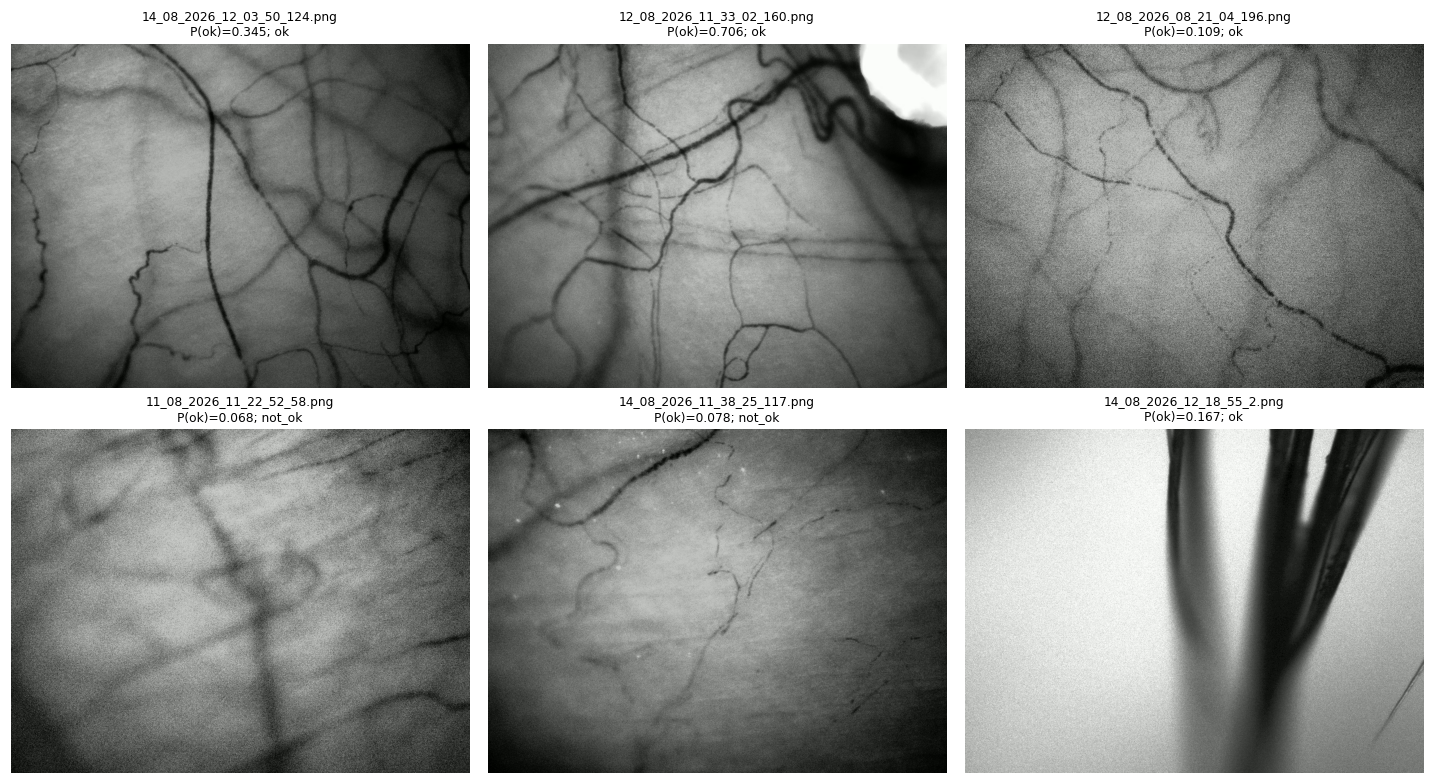

In [3]:
if files:
    from PIL import Image
    chosen = files[:6]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, file in zip(axes.flat, chosen):
        with Image.open(file) as image:
            ax.imshow(image)
        row = output.loc[output.file == str(file)].iloc[0]
        ax.set_title(f'{file.name}\nP(ok)={row.p_ok:.3f}; {row.decision}', fontsize=8)
    plt.show()

## Замер скорости на этом компьютере

Бенчмарк отдельно измеряет чтение/декодирование, четыре признака и классификатор.
Один поток OpenCV, последовательная обработка, batch=1; первые три вызова
прогревочные. Ни хеширование для поиска известных кадров, ни загрузка модели,
ни графики в это время не входят. Файловый кэш ОС может быть прогрет.
Несколько фотографий дают только грубую оценку p95; для устойчивого замера
укажи папку и увеличь `N_BENCHMARK`.

,read_decode_ms,features_ms,head_ms,total_ms
median,15.721,17.823,0.426,34.331
p95,18.945,21.396,0.575,39.429


Фотографий: 30 Последовательно, кадров/с: 28.55
CPU: Intel64 Family 6 Model 158 Stepping 10, GenuineIntel Python: 3.10.0


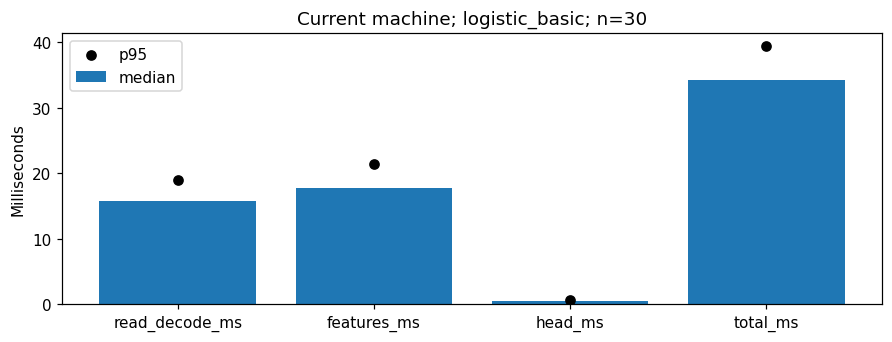

In [4]:
import platform
N_BENCHMARK = 30
benchmark_files = (sorted(PICTURES.glob('*.png'))[:N_BENCHMARK] if not INPUT_PATH
                   else files[:N_BENCHMARK])
if benchmark_files:
    timings = benchmark(benchmark_files, model=MODEL, warmup=3)
    display(timings.drop(columns='file').agg(['median', lambda x: x.quantile(.95)]).rename(index={'<lambda>':'p95'}).round(3))
    print('Фотографий:', len(timings), 'Последовательно, кадров/с:', round(1000/timings.total_ms.mean(), 2))
    print('CPU:', platform.processor(), 'Python:', platform.python_version())
    fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
    names = ['read_decode_ms','features_ms','head_ms','total_ms']
    ax.bar(names, timings[names].median(), label='median')
    ax.scatter(names, timings[names].quantile(.95), color='black', label='p95', zorder=3)
    ax.set(ylabel='Milliseconds', title=f'Current machine; {MODEL}; n={len(timings)}')
    ax.legend(); plt.show()
else:
    print('Для замера нужны фотографии.')

В исходном замере на i5-9300H у LR-4: PNG → решение p50≈63,5 мс,
p95≈140,8 мс; анализ уже декодированного массива p50≈31,3 мс.
Это измерение конкретной реализации и компьютера, а не гарантия частоты видеопотока.
Нельзя складывать медианы отдельных этапов и считать это медианой общей задержки.

Для исходных кадров качество оцениваем по OOF из первого ноутбука;
итоговые прогнозы этого ноутбука показывают работу рабочего экземпляра.